* **Metric:** weekly **ARPU** per user, in UAH — continuous, positive, right-skewed.
* **Baseline:** $\mu_0 = 250$ UAH (3 months of history for the old menu).
* **Cohorts:** `control` = old menu, `test` = new menu (combo deals).
* **Break-even = +15 UAH** — the **decision threshold**. Below this lift the extra revenue does not cover rebuilding the menu and logistics, so the feature is not worth shipping.
* **Design-MDE = +25 UAH** — the **planning threshold**. This is the “clear win” the team sizes the experiment to detect (power 0.8). It is a *different* number from break-even and is used **only** for power/sample planning, never as the ship rule.
* **Direction:** we only ship if the new menu is *better* $\rightarrow$ one-sided test, $H_1 : \mu_{\text{test}} > \mu_{\text{control}}$.
* **Significance level:** $\alpha = 0.05$.

In [2]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib_inline
import seaborn as sns
from scipy.stats import ttest_ind, shapiro, probplot, ks_2samp, f
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.distributions.empirical_distribution import ECDF

from greenbowl_gof import load_my_experiment, load_my_log, arpu_sample, BASELINE, ALPHA
warnings.filterwarnings("ignore")
matplotlib_inline.backend_inline.set_matplotlib_formats("svg")

In [3]:
STUDENT_ID = "ozhelezniakovl@kse.org.ua"
exp = load_my_experiment(STUDENT_ID)

print(f'n_control = {exp.n_control}, n_test = {exp.n_test}')
print(f"control mean = {exp.control.mean():.1f} ₴,  test mean = {exp.test.mean():.1f} ₴")
print(f"observed lift = {exp.test.mean() - exp.control.mean():+.1f} ₴")
print(f"baseline = {BASELINE} ₴,  alpha = {ALPHA}")

n_control = 60, n_test = 12
control mean = 210.6 ₴,  test mean = 412.6 ₴
observed lift = +202.1 ₴
baseline = 250.0 ₴,  alpha = 0.05


## t-test

In [4]:
t_result = ttest_ind(exp.test, exp.control, alternative='greater')
ci_95 = t_result.confidence_interval(confidence_level=0.95)

print(f"p-value: {t_result.pvalue:.3f}")
print(f"T-statistic: {t_result.statistic:.3f}")
print(f"df: {t_result.df}")
print(f"CI: {ci_95.low:.3f} -- {ci_95.high:.3f}")

p-value: 0.001
T-statistic: 3.196
df: 70.0
CI: 96.685 -- inf


## Shapiro–Wilk test and QQ-plot

* При великих n (n > 5000) Шапіро-Вілк починає бачити мікроскропічні різниці, тому починає бачити різницю там де її нема. Відповідно FPR стає великим.

* Якщо дані розподілені ненолрмально ($X \nsim N(\mu, \sigma^2)$) і маленька вибірка (n < 30), користування t-test стає ризиковим. Тому зараз перевірка на нормальність для нас важлива.

In [6]:
def check_normality(sample, alpha=0.05):
    """Version 1. Shapiro–Wilk test + a human-readable verdict."""
    W, p_value = shapiro(sample)
    if p_value > alpha:
        verdict = "✅ do not reject normality → the t-test can be trusted"
    else:
        verdict = "⛔ reject normality → on a small n the t-test is risky"
    return {"W": W, "p_value": p_value, "verdict": verdict}

In [7]:
shapiro_result = check_normality(exp.control)

print("\t Shapiro test")
print(f"W = {shapiro_result["W"]:.3f}")
print(f"p-value = {shapiro_result["p_value"]:.3f}")
print(shapiro_result["verdict"])

	 Shapiro test
W = 0.763
p-value = 0.000
⛔ reject normality → on a small n the t-test is risky


In [8]:
shapiro_result = check_normality(np.log(exp.control))

print("\t Shapiro test with log scale")
print(f"W = {shapiro_result["W"]:.3f}")
print(f"p-value = {shapiro_result["p_value"]:.3f}")
print(shapiro_result["verdict"])

	 Shapiro test with log scale
W = 0.996
p-value = 0.999
✅ do not reject normality → the t-test can be trusted


In [9]:
shapiro_result = check_normality(exp.control)

print("\t Shapitp test")
print(f"W = {shapiro_result["W"]:.3f}")
print(f"p-value = {shapiro_result["p_value"]:.3f}")
print(shapiro_result["verdict"])

	 Shapitp test
W = 0.763
p-value = 0.000
⛔ reject normality → on a small n the t-test is risky


In [10]:
shapiro_result = check_normality(np.log(exp.control))

print("\t Shapitp test with log scale")
print(f"W = {shapiro_result["W"]:.3f}")
print(f"p-value = {shapiro_result["p_value"]:.3f}")
print(shapiro_result["verdict"])

	 Shapitp test with log scale
W = 0.996
p-value = 0.999
✅ do not reject normality → the t-test can be trusted


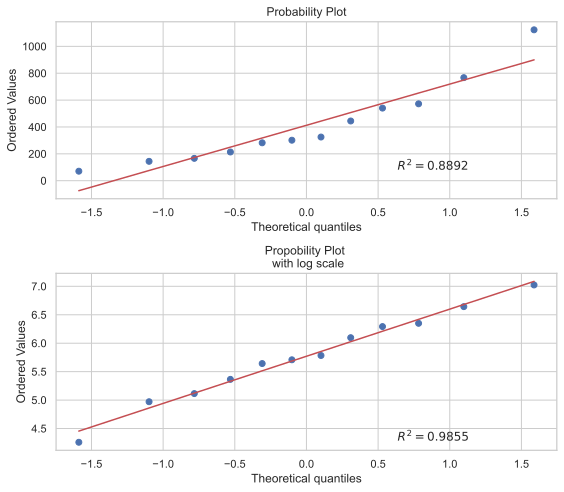

In [11]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(2, 1, figsize=(8, 7))

probplot(exp.test, plot=ax[0], rvalue=True)
probplot(np.log(exp.test), plot=ax[1], rvalue=True)

ax[1].set_title("Propobility Plot \n with log scale")
plt.tight_layout()
plt.show()

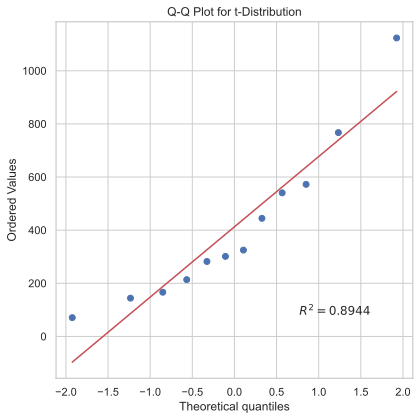

In [12]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 6))

probplot(exp.test, dist="t", sparams=(5,), plot=ax, rvalue=True)

ax.set_title("Q-Q Plot for t-Distribution")
plt.tight_layout()
plt.show()

## The A/A Guardrail: Was the Randomization Honest?

* Можна побачити, що до тесту розподіли були однакові. А під час тесту різні


In [13]:
def same_distribution(x, y, alpha=0.05):
    """Version 2. Two-sample KS: are x and y from the same distribution?"""
    D, p_value = ks_2samp(x, y)
    if p_value > alpha:
        verdict = "✅ distributions do not differ (randomization ok)"
    else:
        verdict = "⛔ distributions differ (suspected bug / effect)"
    return {"D": D, "p_value": p_value, "verdict": verdict}

In [14]:
ks_result = same_distribution(exp.test, exp.control)

print("\t Two-sample Kolmogorov–Smirnov test")
print(f"D: {ks_result["D"]:.3f}")
print(f"p-value: {ks_result["p_value"]:.3f}")
print(ks_result["verdict"])

	 Two-sample Kolmogorov–Smirnov test
D: 0.450
p-value: 0.026
⛔ distributions differ (suspected bug / effect)


In [15]:
ks_result = same_distribution(exp.pre_test, exp.pre_control)

print("\t Two-sample Kolmogorov–Smirnov test (Pre-period)")
print(f"D: {ks_result["D"]:.3f}")
print(f"p-value: {ks_result["p_value"]:.3f}")
print(ks_result["verdict"])

	 Two-sample Kolmogorov–Smirnov test (Pre-period)
D: 0.350
p-value: 0.147
✅ distributions do not differ (randomization ok)


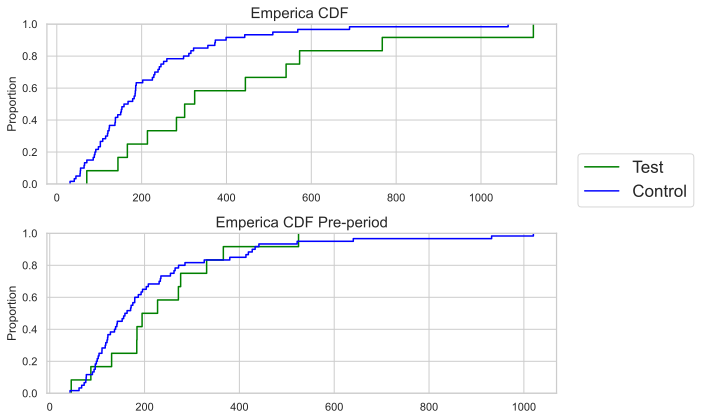

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

sns.ecdfplot(exp.test, ax=ax[0], color="green", label="Test")
sns.ecdfplot(exp.control, ax=ax[0], color="blue", label="Control")

sns.ecdfplot(exp.pre_test, ax=ax[1], color="green")
sns.ecdfplot(exp.pre_control, ax=ax[1], color="blue")

ax[0].set_title("Emperica CDF ", size=15)
ax[1].set_title("Emperica CDF Pre-period", size=15)
fig.legend(loc='upper left', bbox_to_anchor=(1, 0.65), fontsize=17, markerscale=16)

plt.tight_layout()
plt.show()

## Does the Effect Live in the Shape, Not the Mean?

* Welch t-test `reject` &rarr;   $\mu_{\text{test}} > \mu_{\text{control}}$
* Two-sample Kolmogorov–Smirnov test `reject` &rarr; $F_1(x) \neq F_2(x) \quad  $
* f-test `reject` &rarr;  $\sigma_1^2 \neq \sigma_2^2$ (The variances are different)

In [17]:
t_result = ttest_ind(exp.test, exp.control, alternative='greater')
ci_95 = t_result.confidence_interval(confidence_level=0.95)

print("\t Welch t-test")
print(f"p-value: {t_result.pvalue:.3f}")
print(f"T-statistic: {t_result.statistic:.3f}")
print(f"df: {t_result.df}")
print(f"CI: {ci_95.low:.3f} -- {ci_95.high:.3f}")
print("⛔ mean differ")

	 Welch t-test
p-value: 0.001
T-statistic: 3.196
df: 70.0
CI: 96.685 -- inf
⛔ mean differ


In [18]:
ks_result = same_distribution(exp.test, exp.control)

print("\t Two-sample Kolmogorov–Smirnov test")
print(f"D: {ks_result["D"]:.3f}")
print(f"p-value: {ks_result["p_value"]:.3f}")
print(ks_result["verdict"])

	 Two-sample Kolmogorov–Smirnov test
D: 0.450
p-value: 0.026
⛔ distributions differ (suspected bug / effect)


In [19]:
ks_result = same_distribution(exp.pre_test, exp.pre_control)

print("\t Two-sample Kolmogorov–Smirnov test (Pre-period)")
print(f"D: {ks_result["D"]:.3f}")
print(f"p-value: {ks_result["p_value"]:.3f}")
print(ks_result["verdict"])

	 Two-sample Kolmogorov–Smirnov test (Pre-period)
D: 0.350
p-value: 0.147
✅ distributions do not differ (randomization ok)


### Is Variance differ?й

In [20]:
def f_test(sample_1, sample_2):

    var1 = np.var(sample_1, ddof=1)
    var2 = np.var(sample_2, ddof=1)

    df1 = len(sample_1) - 1
    df2 = len(sample_2) - 1

    if var1 > var2:
        f_stat = var1 / var2
        p_value = f.sf(f_stat, df1, df2)
    else:
        f_stat = var2/ var1
        p_value = f.sf(f_stat, df2, df1)
    return {"f_stat": f_stat, "p_value": p_value}


In [21]:
f_test_result = f_test(exp.pre_test, exp.pre_control)

print("\t Two-sampple F-test")
print(f"F-stat: {f_test_result["f_stat"]:.3f}")
print(f"p-value: {f_test_result["p_value"]:.3f}")
print("⛔ reject equal variances → the variance are differ"
      if f_test_result["p_value"] <= 0.05 else
      "✅ do not reject → equal variances")

	 Two-sampple F-test
F-stat: 2.068
p-value: 0.094
✅ do not reject → equal variances


In [22]:
f_test_result = f_test(exp.test, exp.control)

print("\t Two-sampple F-test")
print(f"F-stat: {f_test_result["f_stat"]:.3f}")
print(f"p-value: {f_test_result["p_value"]:.3f}")
print("⛔ reject equal variances → the variance are differ"
               if f_test_result["p_value"] <= 0.05 else
               "✅ do not reject → equal variances")

	 Two-sampple F-test
F-stat: 2.985
p-value: 0.003
⛔ reject equal variances → the variance are differ


### Expected Value and Variance

The expected value (mean) of a log-normal distribution is:

$$E[X] = \exp\left( \mu + \frac{\sigma^2}{2} \right)$$

The variance of a log-normal distribution is:

$$\text{Var}(X) = \left[ \exp(\sigma^2) - 1 \right] \exp(2\mu + \sigma^2)$$

[Sourse](https://github.com/djeada/Statistics-Notes/blob/main/notes/probability_distributions/continuous_distributions/log_normal_distribution.md?plain=1#probability-density-function-pdf)

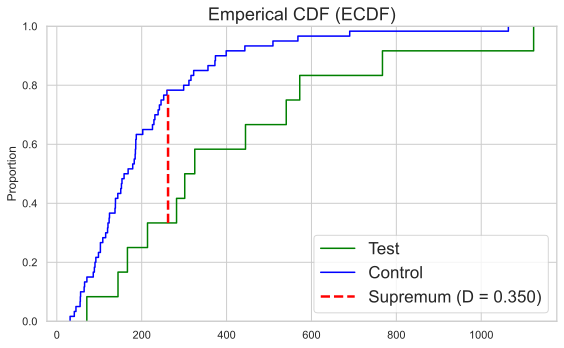

In [23]:
ecdf_test = ECDF(exp.test)
ecdf_control = ECDF(exp.control)
pooled_x = np.sort(np.concatenate([exp.test, exp.pre_control]))
test_values = ecdf_test(pooled_x)
control_values = ecdf_control(pooled_x)
difference = np.abs(test_values - control_values)
max_ind = np.argmax(difference)

test_value = test_values[max_ind]
control_value = control_values[max_ind]
sup_x = pooled_x[max_ind]


fig, ax = plt.subplots(figsize=(8, 5))

sns.ecdfplot(exp.test, ax=ax, color="green", label="Test")
sns.ecdfplot(exp.control, ax=ax, color="blue", label="Control")
ax.set_title("Emperical CDF (ECDF)", fontsize=18)
plt.vlines(
    x=sup_x,
    ymin=test_value,
    ymax=control_value,
    colors='red',
    linestyles='--',
    linewidth=2.5,
    label=f'Supremum (D = {ks_result["D"]:.3f})'
)

plt.legend(fontsize=17, markerscale=16, loc='lower right')
plt.tight_layout()
plt.show()

### Zero-inflation probe

* $ARPU \neq 0$ не існує чеків з нульовим чеків не буває

* Додамо штучно ARPU контрольну і тестову групи нульві ARPU

In [24]:
contror_wzero = np.append(exp.control, np.zeros(10))
test_wzero = np.append(exp.test, np.zeros(4))

q1 = np.sum(np.where(test_wzero == 0, 1, 0))
q2 = np.sum(np.where(contror_wzero == 0, 1, 0))

z_stat, p_value = proportions_ztest([q1, q2], [len(test_wzero), len(contror_wzero)], alternative='larger')

print("\t Two-sample Z-test")
print(f"Z-stat: {z_stat:.3f}")
print(f"p-value: {p_value:.3f}")
print(r"✅ Don't reject")

	 Two-sample Z-test
Z-stat: 1.047
p-value: 0.147
✅ Don't reject


# The Independence Check


In [25]:
both_group_user = len(np.intersect1d(exp.uid_test, exp.uid_control))

print(f"Users appear in both groups (number): {both_group_user}")
print(rf"✅ Independ Groups" if both_group_user==0 else "Depend")

Users appear in both groups (number): 0
✅ Independ Groups


# Validate My Guardrail with Monte Carlo


In [26]:
def ks_fpr(gen, n, n_exps=3000, alpha=0.05, seed=73):
    """FPR of the two-sample KS under H0 (both groups from gen) + 95% Wilson CI."""
    np.random.seed(seed)
    rej = 0
    for _ in range(n_exps):
        rej += ks_2samp(gen(n), gen(n)).pvalue < alpha
    low, high = proportion_confint(rej, n_exps, alpha=0.05, method="wilson")
    return {"fpr": rej / n_exps, "ci_low": low, "ci_high": high}

arpu_aa = lambda n: arpu_sample(250, n)



In [27]:
n_exps = 100_000

print(f"Number of experiments {n_exps}")
for n in (20, 100, 500, 1000):
    result = ks_fpr(arpu_aa, n, n_exps=n_exps)
    inside = result['ci_low'] <= 0.05 <= result['ci_high']
    print(f"n: {n} \t  FPR: {result['fpr']:.4f} \t ",
          f"CI: {result['ci_low']:.3f} --  {result['ci_high']:.3f}",
          f"{'✅' if inside else '🟡 conservative'}")

Number of experiments 100000
n: 20 	  FPR: 0.0334 	  CI: 0.032 --  0.035 🟡 conservative
n: 100 	  FPR: 0.0357 	  CI: 0.035 --  0.037 🟡 conservative
n: 500 	  FPR: 0.0503 	  CI: 0.049 --  0.052 ✅
n: 1000 	  FPR: 0.0482 	  CI: 0.047 --  0.050 🟡 conservative


In [28]:
def ks_get_power(gen_c, gen_t, n, n_exps=10_000,
                     alpha=0.05):
    """Power of KS on paired (before/after) data with a shared component."""
    rej = 0
    for _ in range(n_exps):
        rej += ks_2samp(gen_c(n), gen_t(n)).pvalue < alpha
    return  rej/n_exps


In [29]:
n_exps = 10_000
n = 300

print(f"Number of experiments {n_exps} \t Sample size: {n}")
for diff in np.arange(10, 100, 10):
    arpu_sample_1 = lambda n: arpu_sample(250, n)
    arpu_sample_2 = lambda n: arpu_sample(250 + diff, n)
    result = ks_get_power(arpu_sample_1, arpu_sample_2, n=n, n_exps=n_exps)
    valid = result >= 0.8
    print(f"Mean diffrence: {diff} \t Power: {result:.4f} \t ",
          f"{'✅' if valid else '🟡 Need more N'}")

Number of experiments 10000 	 Sample size: 300
Mean diffrence: 10 	 Power: 0.0882 	  🟡 Need more N
Mean diffrence: 20 	 Power: 0.2432 	  🟡 Need more N
Mean diffrence: 30 	 Power: 0.4811 	  🟡 Need more N
Mean diffrence: 40 	 Power: 0.7105 	  🟡 Need more N
Mean diffrence: 50 	 Power: 0.8823 	  ✅
Mean diffrence: 60 	 Power: 0.9647 	  ✅
Mean diffrence: 70 	 Power: 0.9913 	  ✅
Mean diffrence: 80 	 Power: 0.9980 	  ✅
Mean diffrence: 90 	 Power: 0.9999 	  ✅


In [30]:
log = load_my_log(STUDENT_ID)
log

,city,cuisine,arpu
0,city_0,pizza,113.022471
1,city_0,pizza,105.828319
2,city_0,pizza,79.798850
3,city_0,pizza,1080.470774
4,city_0,pizza,187.016757
...,...,...,...
100473,city_39,salad,254.451793
100474,city_39,salad,105.013149
100475,city_39,salad,115.287976
100476,city_39,salad,353.676577


In [31]:
def thousand_aa_tests(log, alpha=0.05, lift=0.0, seed=100):
    rng, rej, k = np.random.default_rng(seed), 0, 0
    for _, gdf in log.groupby(["city", "cuisine"]):
        arpu = gdf["arpu"].to_numpy()
        idx  = rng.permutation(len(arpu))      # INDEPENDENT split per slice
        half = len(arpu) // 2
        control = arpu[idx[:half]]
        test    = arpu[idx[half:2 * half]] * (1 + lift)   # lift=0 -> A/A
        rej += ks_2samp(test, control).pvalue < alpha
        k   += 1
    low, high = proportion_confint(rej, k, alpha=0.05, method="wilson")
    return {"fpr": rej / k, "ci_low": low, "ci_high": high}

In [32]:
result = thousand_aa_tests(log)

print("\t Real-log A/A Test")
print(f"Emperical FPR: {result["fpr"]:.3f}")
print(f"CI: {result["ci_low"]:.3f} -- {result["ci_high"]:.3f}")
print(f"{'✅ Valid' if result["ci_low"] < 0.05 < result["ci_high"] else '⛔ Not Valid'}")

	 Real-log A/A Test
Emperical FPR: 0.056
CI: 0.036 -- 0.087
✅ Valid


# Memo

* t-тест каже, що середнє збільшилось (p-value = 0.001)
* Також змінилися дисперсія каже f-тест (p-value = 0.03)
* Тож змінилися розподіл нам це пітверджує Колмогоров-Смирнов (p-value = 0.03)
* Контрольна і тестова групи мають log-norm розподіл, тому варто розглядати в log scale
* За попередній поредній період розподіли були однакові це пітверджує Колмогоров-Смирнов (p-value = 0.03) тож розподіли результат експеремунту.

##  Висновок
* Варто впроваджувати
* Через зміну середньго змінилася дисперсія та форма розподілу

##  Обмеження
* Шум при Монте-Карло. Хоча формально Емпіричний `FPR` не попадає в `CI` різниця маленька, тому я думаю, що це шум.